# Gaussian proposals and the MPPI update

How much influence does each sampled command have on the next plan? A one-step velocity-control problem lets us inspect every candidate, verify the MPPI update against the planner, and compare the result with a known quadratic minimum. [Plan a complete trajectory](SamplingPlanner.ipynb)

GTSAM Copyright 2010-2026, Georgia Tech Research Corporation,
Atlanta, Georgia 30332-0415

All Rights Reserved

Authors: Akash Ratheesh and Frank Dellaert (see THANKS for the full author list)

See LICENSE for the license information

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/borglab/gtsam/blob/develop/gtsam/planning/doc/MPPI.ipynb)

In [1]:
try:
    import google.colab
    %pip install --quiet gtsam-develop plotly==6.3.1
except ImportError:
    pass

In [2]:
from html import escape
import numpy as np
import gtsam
from gtsam.symbol_shorthand import U, X
from plotly.subplots import make_subplots
from IPython.display import HTML, display

teal, orange, slate = "#087B78", "#B65025", "#536577"
plotly_js = "https://cdn.plot.ly/plotly-3.1.1.min.js"

## Couple a prediction to a graph cost

A point starts at $x_0=0$ m and holds a velocity $u$ for one second, reaching $x_1=x_0+u\,\Delta t$. A prior with precision $q$ attracts $x_1$ to 1 m. A prior with precision $r$ penalizes the command. Evaluating the graph gives $S(u)=\tfrac12 q(x_1-1)^2+\tfrac12 r u^2$.

In [3]:
dt, start, goal = 1.0, 0.0, 1.0
q, r = 8.0, 0.5
cost = gtsam.NonlinearFactorGraph()
cost.add(gtsam.PriorFactorVector(X(1), np.array([goal]), gtsam.noiseModel.Isotropic.Precision(1, q)))
cost.add(gtsam.PriorFactorVector(U(0), np.zeros(1), gtsam.noiseModel.Isotropic.Precision(1, r)))
planner = gtsam.SamplingPlannerVectorVector([X(0), X(1)], [U(0)], dt)
seed = gtsam.Values()
seed.insert(X(0), np.array([start]))

def velocity(state, control):
    return control

def rollout_cost(speed):
    return cost.error(planner.rollout(seed, np.array([[speed]]), velocity))

## Inspect the proposal

`GaussianProposal.initialize` makes a search state whose mean is the nominal control matrix. The proposal draws independent Gaussian perturbations with covariance $0.8^2$ at each time step. For $K$ trajectories of length $H$ in $M$ control dimensions, `sample` returns an $M\times(KH)$ matrix. The $H$ consecutive columns at offset $iH$ encode candidate $i$. Here $M=H=1$, so each column holds one candidate speed.

In [4]:
initial, count = 0.0, 128
nominal = np.array([[initial]])
covariance = np.array([[0.8**2]])
proposal = gtsam.GaussianProposal(covariance, count, 42)
search = proposal.initialize(nominal)
initial_values = planner.rollout(seed, nominal, velocity)
batch = proposal.sample(search, initial_values, dt)
candidates = batch.controls[0]
scores = planner.rolloutAndScore(cost, initial_values, batch.controls, velocity)
np.testing.assert_allclose(scores, [rollout_cost(speed) for speed in candidates])

## Follow the weighted update

A sample receives weight $w_i=\exp[-\beta(S_i-S_{\min})]/\sum_j\exp[-\beta(S_j-S_{\min})]$, where $S_i$ is its graph error and $\beta$ the inverse temperature. The Gaussian proposal updates the nominal command to $\sum_i w_i u_i$. We reproduce the same batch by seeding a fresh proposal and check the full planner's answer. The derivative of the quadratic graph error gives an independent reference, $u^*=q\Delta t(g-x_0)/(q\Delta t^2+r)$.

In [5]:
rule = gtsam.MPPI(1.0)
weights = rule.weights(scores)
rule.apply(proposal, search, batch, scores)
updated = float(search.mean[0, 0])
np.testing.assert_allclose(updated, weights @ candidates)
replay = gtsam.GaussianProposal(covariance, count, 42)
plan = planner.optimize(cost, initial_values, velocity, replay, rule, 1)
np.testing.assert_allclose(planner.nominalControls(plan)[0, 0], updated)
optimum = q * dt * (goal - start) / (q * dt**2 + r)
print(f"Initial command {initial:.3f}, MPPI update {updated:.3f}, "
      f"quadratic optimum {optimum:.3f} m/s")
print(f"Graph error {rollout_cost(initial):.3f} → {rollout_cost(updated):.3f}")

Initial command 0.000, MPPI update 0.844, quadratic optimum 0.941 m/s
Graph error 4.000 → 0.275


The upper panel shows the objective across commands. The lower panel shows how strongly the 128 samples influence the update. Raising the inverse temperature concentrates the weights on the lowest-cost commands. Interactive figures require an internet connection.

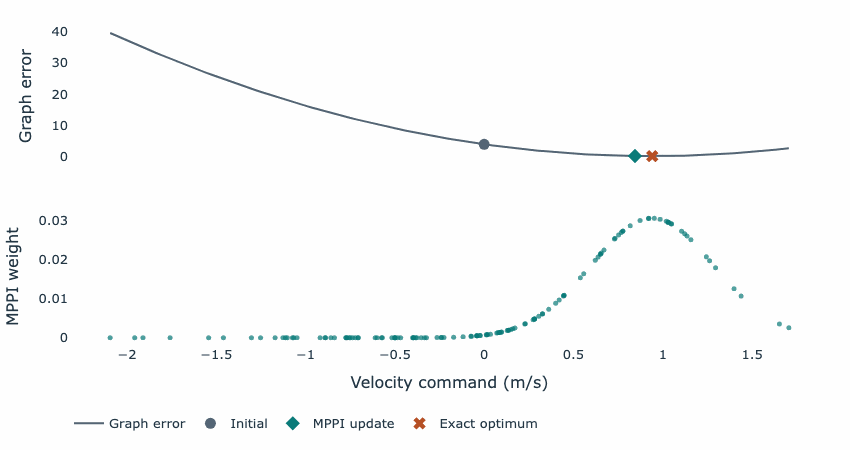

In [6]:
fig = make_subplots(rows=2, cols=1, shared_xaxes=True, vertical_spacing=0.14)
grid = np.linspace(candidates.min(), candidates.max(), 150)
fig.add_scatter(x=grid, y=[rollout_cost(u) for u in grid], mode="lines",
                line=dict(color=slate), name="Graph error", row=1, col=1)
for u, label, color, symbol in [(initial, "Initial", slate, "circle"),
                                (updated, "MPPI update", teal, "diamond"),
                                (optimum, "Exact optimum", orange, "x")]:
    fig.add_scatter(x=[u], y=[rollout_cost(u)], mode="markers", name=label,
                    marker=dict(color=color, symbol=symbol, size=11), row=1, col=1)
order = np.argsort(candidates)
fig.add_scatter(x=candidates[order], y=weights[order], mode="markers",
                marker=dict(color=teal, size=5, opacity=0.7), name="Sample weights",
                customdata=scores[order], showlegend=False,
                hovertemplate="u = %{x:.3f} m/s<br>Cost %{customdata:.3f}<br>Weight %{y:.4f}<extra></extra>",
                row=2, col=1)
fig.update_yaxes(title_text="Graph error", range=[-0.06 * scores.max(), 1.04 * scores.max()], row=1, col=1)
fig.update_yaxes(title_text="MPPI weight", range=[-0.06 * weights.max(), 1.08 * weights.max()], row=2, col=1)
fig.update_xaxes(title_text="Velocity command (m/s)", row=2, col=1)
fig.update_layout(template="plotly_white", height=450, margin=dict(l=63, r=20, t=28, b=65),
                  font=dict(size=13, color="#243744"), hoverlabel=dict(namelength=-1),
                  legend=dict(orientation="h", y=-0.20, x=0))
# Give Plotly its own document so the figure also runs in the published guide.
plot = fig.to_html(full_html=False, include_plotlyjs=plotly_js,
                   config={"displaylogo": False, "responsive": True})
document = '<!doctype html><meta charset="utf-8"><style>body{margin:0}</style>' + plot
display(HTML(f'<iframe title="Gaussian proposals and the MPPI update" style="width:100%;border:0" '
             f'height="{fig.layout.height}" srcdoc="{escape(document, quote=True)}"></iframe>'))